# Agentes de búsqueda adversaria para el 4 en raya

**Proyecto final · Representación y solución automática de problemas**
Escuela de Ingeniería, Ciencia y Tecnología · Universidad del Rosario

**Integrante:** Juan Sebastián Arroyo Zúñiga

---

## Objetivo

En este notebook se crea una instancia del entorno **4 en raya (Conecta 4)**, se muestran sus principales atributos y métodos, y se ejemplifica la aplicación de los tres algoritmos implementados:

1. **Minimax con profundidad limitada** (no informado).
2. **Alfa-beta con cutoff y función de evaluación**, H-Minimax (informado), con dos heurísticas: `h1` (ventanas de amenaza) y `h2` (control posicional).
3. **Monte Carlo Tree Search** con UCB1 (basado en simulación).

El entorno y los agentes siguen la definición formal de juegos y las clases del taller de Juegos del curso (`Triqui`, `Agent`, `PlfromAlgo`, `EnvfromGameAndPl2`, `Episode`, `compara_funciones`, `ArbolBusquedaJuego`).

## Secciones

1. [El entorno](#entorno)
2. [Funciones de evaluación](#heuristicas)
3. [Algoritmo minimax](#minimax)
4. [Algoritmo alfa-beta con cutoff](#alfabeta)
5. [Monte Carlo Tree Search](#mcts)
6. [Traza de la búsqueda](#traza)
7. [Comparación sobre la misma instancia](#comparacion)
8. [Partidas completas con las clases del curso](#partidas)
9. [Torneo y optimalidad](#torneo)
10. [Resultados de los experimentos del informe](#experimentos)

## Dependencias

In [1]:
# El notebook está en la carpeta notebooks/: se agrega la carpeta del
# proyecto a la ruta para poder importar el paquete conecta4
import os
import sys
sys.path.insert(0, os.path.abspath('..'))

**De Python:**

In [2]:
import random
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings('ignore')

**Del proyecto:**

In [3]:
from conecta4.juego import Conecta4, VENTANAS
from conecta4.heuristicas import (TABLA_POSICIONAL, caracteristicas_h1,
                                  h1_ventanas, h2_posicional)
from conecta4.agentes import (AgenteMinimax, AgenteAlfaBeta, AgenteMCTS,
                              PlfromAlgo, Random)
from conecta4.config import crear_agente, PARAMETROS
from conecta4.experimentos import (comparar_jugada, jugar_partida, torneo,
                                   tabla_posiciones)
from conecta4.solver import SolverExacto
from conecta4.tiempos import compara_funciones
from conecta4.utils import EnvfromGameAndPl2, Episode

---
## 1. El entorno <a class="anchor" id="entorno"></a>

El entorno es la clase `Conecta4` del módulo `conecta4/juego.py`. Igual que la clase `Triqui` del taller de Juegos, se define con las características de un **juego competitivo**:

* **estado_inicial:** tablero desde el cual comienza el juego (por defecto, el tablero $6\times 7$ vacío).
* **player(s):** jugador al que le corresponde el turno en `s` (1 = rojas, 2 = amarillas).
* **acciones(s):** columnas en las que se puede soltar una ficha.
* **resultado(s, a):** tablero que resulta de soltar una ficha en la columna `a`.
* **es_terminal(s):** indica si el juego terminó en `s`.
* **utilidad(s, j):** utilidad del estado terminal `s` para el jugador `j`.

### Creación de una instancia y atributos

In [4]:
juego = Conecta4()
print('Filas:', juego.filas)
print('Columnas:', juego.columnas)
print('Estado inicial (matriz 6x7; 0 = vacía, 1 = jugador 1, 2 = jugador 2):')
print(juego.estado_inicial)

Filas: 6
Columnas: 7
Estado inicial (matriz 6x7; 0 = vacía, 1 = jugador 1, 2 = jugador 2):
[[0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]


Un **estado** es una matriz de numpy de 6 filas por 7 columnas. La fila 0 es la fila superior del tablero y la fila 5 la inferior. El jugador en turno no se guarda: se deduce de la paridad del número de fichas.

### Métodos principales

In [5]:
s = juego.estado_inicial
print('Le corresponde el turno al jugador:', juego.player(s))   # Debe ser 1
print('Acciones posibles:', juego.acciones(s))                   # 0 a 6
print('¿Juego terminado?:', juego.es_terminal(s))                # False
print('Utilidad:', juego.utilidad(s, 1))                         # None

Le corresponde el turno al jugador: 1
Acciones posibles: [0, 1, 2, 3, 4, 5, 6]
¿Juego terminado?: False
Utilidad: None


La ficha del jugador 1 cae a la fila inferior: 1
La ficha del jugador 2 queda encima: 2
El estado original no se modifica: True
Ahora le corresponde el turno al jugador: 1


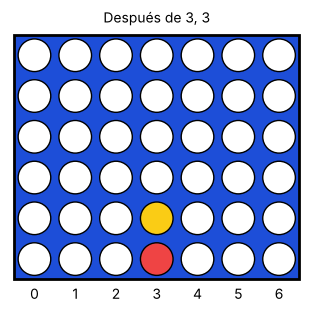

In [6]:
# El jugador 1 juega en la columna 3 y el jugador 2 responde en la misma
s1 = juego.resultado(s, 3)
s2 = juego.resultado(s1, 3)
print('La ficha del jugador 1 cae a la fila inferior:', s1[5, 3])
print('La ficha del jugador 2 queda encima:', s2[4, 3])
print('El estado original no se modifica:', np.count_nonzero(s) == 0)
print('Ahora le corresponde el turno al jugador:', juego.player(s2))
juego.render(s2, titulo='Después de 3, 3')

El método `render` dibuja el tablero con matplotlib (como `Triqui.render`) y `a_texto` lo devuelve como texto.

### Estados terminales y utilidad

El juego termina cuando hay cuatro en línea o cuando el tablero está lleno. La utilidad premia ganar rápido y perder tarde:

$$\text{utilidad}(s, j)=\begin{cases}+(43-n) & \text{si gana } j\\ -(43-n) & \text{si pierde } j\\ 0 & \text{si hay empate}\end{cases}$$

donde $n$ es el número de fichas en el tablero. Es un juego de **suma cero**: `utilidad(s, 1) == -utilidad(s, 2)`.

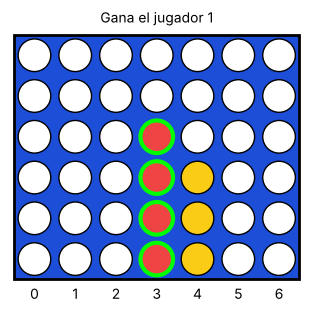

¿Juego terminado?: True
Ganador: 1
Casillas de la línea ganadora: [(2, 3), (3, 3), (4, 3), (5, 3)]
Acciones posibles: []
Utilidad para el jugador 1: 36 (43 - 7 fichas)
Utilidad para el jugador 2: -36
Juego terminado. ¡Gana el jugador 1!


In [7]:
# El método desde_jugadas construye un estado a partir de una secuencia
# de columnas: el jugador 1 hace cuatro en línea vertical en la columna 3
s_final = juego.desde_jugadas([3, 4, 3, 4, 3, 4, 3])
juego.render(s_final, titulo='Gana el jugador 1')
print('¿Juego terminado?:', juego.es_terminal(s_final))
print('Ganador:', juego.ganador(s_final))
print('Casillas de la línea ganadora:', juego.linea_ganadora(s_final))
print('Acciones posibles:', juego.acciones(s_final))
print('Utilidad para el jugador 1:', juego.utilidad(s_final, 1), '(43 - 7 fichas)')
print('Utilidad para el jugador 2:', juego.utilidad(s_final, 2))
print(juego.give_result(s_final))

Para saber si alguien ganó, el entorno revisa las **69 ventanas** (grupos de cuatro casillas consecutivas): 24 horizontales, 21 verticales y 24 diagonales.

In [8]:
print('Forma de la matriz de ventanas:', VENTANAS.shape)
print('Primeras tres ventanas (índices planos fila*7 + columna):')
print(VENTANAS[:3])

Forma de la matriz de ventanas: (69, 4)
Primeras tres ventanas (índices planos fila*7 + columna):
[[0 1 2 3]
 [1 2 3 4]
 [2 3 4 5]]


### Generador y editor de instancias

El estado inicial se puede cambiar. `desde_jugadas` crea una posición jugando una secuencia de columnas, `jugadas_aleatorias` genera posiciones aleatorias **reproducibles** (con semilla) y `es_legal` verifica que una matriz sea una posición válida.

In [9]:
rng = random.Random(1)
jugadas = juego.jugadas_aleatorias(12, rng)
print('Secuencia aleatoria (semilla 1):', jugadas)
s_azar = juego.desde_jugadas(jugadas)
print(juego.a_texto(s_azar))
print('¿Posición legal?:', juego.es_legal(s_azar))

# Una matriz con una ficha flotando no es una posición legal
flotando = np.zeros((6, 7), dtype=np.int8)
flotando[2, 3] = 1
print('¿Posición legal?:', juego.es_legal(flotando))

# Un juego puede empezar desde cualquier instancia
juego_editado = Conecta4(estado_inicial=s_azar)
print('Turno en la instancia editada:', juego_editado.player(juego_editado.estado_inicial))

Secuencia aleatoria (semilla 1): [1, 4, 6, 6, 6, 0, 2, 0, 3, 6, 3, 3]
. . . . . . .
. . . . . . .
. . . . . . O
. . . O . . X
O . . X . . O
O X X X O . X
0 1 2 3 4 5 6
¿Posición legal?: (True, '')
¿Posición legal?: (False, 'Hay fichas flotando en la columna 3.')
Turno en la instancia editada: 1


---
## 2. Funciones de evaluación <a class="anchor" id="heuristicas"></a>

Cuando la búsqueda llega a la profundidad límite sin que el juego termine, se usa una **función de evaluación** para estimar qué tan bueno es el tablero para MAX (igual que en el agente `ChessFinalist1` del taller). Las dos heurísticas devuelven valores en $(-1, 1)$, de modo que nunca superan la utilidad de una victoria o de una derrota reales.

**h2 (control posicional):** cada casilla vale el número de ventanas que pasan por ella. Se suman las casillas propias y se restan las del rival.

[[ 3  4  5  7  5  4  3]
 [ 4  6  8 10  8  6  4]
 [ 5  8 11 13 11  8  5]
 [ 5  8 11 13 11  8  5]
 [ 4  6  8 10  8  6  4]
 [ 3  4  5  7  5  4  3]]
Suma de la tabla: 276 = 69 ventanas x 4 casillas


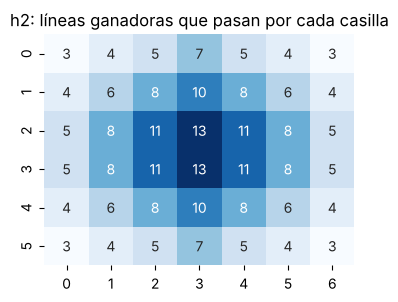

In [10]:
print(TABLA_POSICIONAL)
print('Suma de la tabla:', TABLA_POSICIONAL.sum(), '= 69 ventanas x 4 casillas')
fig, ax = plt.subplots(figsize=(4, 3))
sns.heatmap(TABLA_POSICIONAL, annot=True, cmap='Blues', cbar=False, ax=ax)
ax.set_title('h2: líneas ganadoras que pasan por cada casilla')
plt.show()

In [11]:
centro = juego.desde_jugadas([3])
borde = juego.desde_jugadas([0])
print('h2 con la ficha en el centro:', round(h2_posicional(centro, 1), 4))
print('h2 con la ficha en el borde: ', round(h2_posicional(borde, 1), 4))

h2 con la ficha en el centro: 0.0254
h2 con la ficha en el borde:  0.0109


**h1 (ventanas de amenaza):** se cuentan las ventanas con 3 fichas propias y 1 vacía, 2 propias y 2 vacías, 3 del rival y 1 vacía, y 2 del rival y 2 vacías. La evaluación es la suma ponderada `np.dot(pesos, valores)` con pesos `[6, 3, -5, -2]`, dividida por una constante para que quede en $(-1, 1)$.

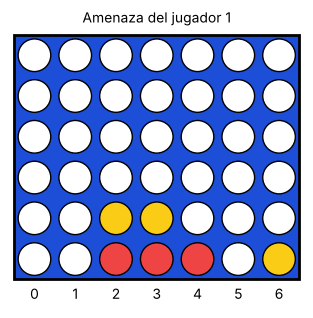

Características [3 propias, 2 propias, 3 rival, 2 rival]: [2, 1, 0, 3]
h1 para el jugador 1: 0.0217
h1 para el jugador 2: -0.0072


In [12]:
# El jugador 1 tiene tres fichas seguidas en la fila inferior
s_amenaza = juego.desde_jugadas([2, 2, 3, 3, 4, 6])
juego.render(s_amenaza, titulo='Amenaza del jugador 1')
print('Características [3 propias, 2 propias, 3 rival, 2 rival]:',
      caracteristicas_h1(s_amenaza, 1))
print('h1 para el jugador 1:', round(h1_ventanas(s_amenaza, 1), 4))
print('h1 para el jugador 2:', round(h1_ventanas(s_amenaza, 2), 4))

---
## 3. Algoritmo minimax <a class="anchor" id="minimax"></a>

`AgenteMinimax` implementa el pseudocódigo del taller (`minimax_search`, `max_value`, `min_value`) con un criterio de corte `is_cutoff`: si se llega a la profundidad límite `max_lim` sin que el juego termine se devuelve 0. Es un algoritmo **no informado**: solo usa la utilidad de los estados terminales.

MAX es siempre el jugador que decide. Probamos el agente en dos tableros: uno en el que puede ganar y otro en el que debe bloquear.

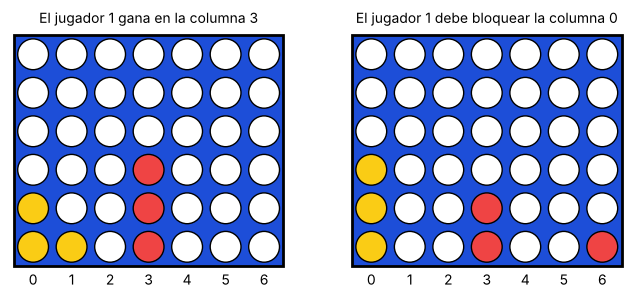

In [13]:
gana_en_1 = juego.desde_jugadas([3, 0, 3, 0, 3, 1])
bloqueo = juego.desde_jugadas([3, 0, 3, 0, 6, 0])
fig, ejes = plt.subplots(1, 2, figsize=(8, 3.4))
juego.render(gana_en_1, ax=ejes[0], titulo='El jugador 1 gana en la columna 3')
juego.render(bloqueo, ax=ejes[1], titulo='El jugador 1 debe bloquear la columna 0')
plt.show()

In [14]:
minimax = AgenteMinimax(juego, max_lim=4, semilla=0)
print('Computador juega en:', minimax.decidir(gana_en_1))   # Debe ser 3
print('Valor de cada columna:', minimax.metricas.valores_acciones)
print('Computador juega en:', minimax.decidir(bloqueo))     # Debe ser 0
print('Valor de cada columna:', minimax.metricas.valores_acciones)

Computador juega en: 3
Valor de cada columna: {0: 0.0, 1: 0.0, 2: 0.0, 3: 36, 4: 0.0, 5: 0.0, 6: 0.0}
Computador juega en: 0
Valor de cada columna: {0: 0.0, 1: -35, 2: -35, 3: -35, 4: -35, 5: -35, 6: -35}


En el primer tablero la columna 3 vale $+36$ (victoria con 7 fichas: $43-7$). En el segundo, cualquier columna distinta de la 0 vale $-35$ (derrota con 8 fichas).

Cada decisión guarda sus **métricas**:

In [15]:
minimax.decidir(juego.estado_inicial)
pd.Series(minimax.metricas.como_dict())

algoritmo           Minimax (d=4)
tiempo                   0.036716
nodos_generados              2800
nodos_expandidos              400
memoria_max                     5
profundidad_max                 4
podas                           0
evaluaciones                 2401
terminales                      0
simulaciones                    0
valor                         0.0
accion                          0
dtype: object

Con profundidad 4 desde el tablero vacío se generan $7+7^2+7^3+7^4=2800$ nodos y se expanden $1+7+7^2+7^3=400$. La memoria es la pila de la búsqueda en profundidad: 5 nodos.

---
## 4. Algoritmo alfa-beta con cutoff <a class="anchor" id="alfabeta"></a>

`AgenteAlfaBeta` adapta el método `_H_minimax_alfa_beta` de `ChessFinalist1`: es minimax con **poda alfa-beta** (revisando las columnas del centro hacia los bordes) y con una **función de evaluación** en la profundidad límite. Es el algoritmo **informado**.

In [16]:
for heuristica in ['h1', 'h2']:
    alfabeta = AgenteAlfaBeta(juego, max_lim=5, heuristica=heuristica)
    print(f'--- Alfa-beta con {heuristica} ---')
    print('Gana en 1  -> juega en:', alfabeta.decidir(gana_en_1))
    print('Bloqueo    -> juega en:', alfabeta.decidir(bloqueo))
    print('Tablero vacío -> juega en:', alfabeta.decidir(juego.estado_inicial),
          '| nodos generados:', alfabeta.metricas.nodos_generados,
          '| podas:', alfabeta.metricas.podas)

--- Alfa-beta con h1 ---
Gana en 1  -> juega en: 3
Bloqueo    -> juega en: 0
Tablero vacío -> juega en: 3 | nodos generados: 856 | podas: 138
--- Alfa-beta con h2 ---
Gana en 1  -> juega en: 3


Bloqueo    -> juega en: 0
Tablero vacío -> juega en: 3 | nodos generados: 755 | podas: 144


**La poda no cambia la decisión.** Si a alfa-beta se le quita la heurística (`heuristica='nula'`), debe obtener exactamente el mismo valor que minimax a la misma profundidad, pero generando muchos menos nodos:

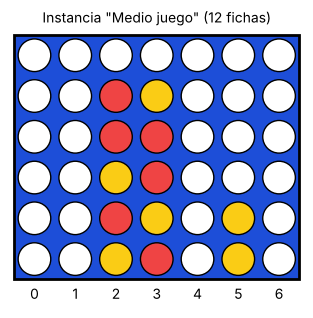

,profundidad,valor minimax,valor alfa-beta,nodos minimax,nodos alfa-beta,podas
0,1,0.0,0.0,7,7,0
1,2,0.0,0.0,54,19,6
2,3,0.0,0.0,359,64,11
3,4,0.0,0.0,2284,150,52
4,5,0.0,0.0,13926,390,92
5,6,0.0,0.0,84294,958,308


In [17]:
medio_juego = juego.desde_jugadas([3, 3, 3, 2, 3, 3, 2, 2, 2, 5, 2, 5])
juego.render(medio_juego, titulo='Instancia "Medio juego" (12 fichas)')
filas = []
for d in range(1, 7):
    minimax = AgenteMinimax(juego, max_lim=d, semilla=0)
    sin_h = AgenteAlfaBeta(juego, max_lim=d, heuristica='nula')
    minimax.decidir(medio_juego)
    sin_h.decidir(medio_juego)
    filas.append({'profundidad': d,
                  'valor minimax': minimax.metricas.valor,
                  'valor alfa-beta': sin_h.metricas.valor,
                  'nodos minimax': minimax.metricas.nodos_generados,
                  'nodos alfa-beta': sin_h.metricas.nodos_generados,
                  'podas': sin_h.metricas.podas})
pd.DataFrame(filas)

---
## 5. Monte Carlo Tree Search <a class="anchor" id="mcts"></a>

`AgenteMCTS` adapta el método `program` de `ChessFinalist2` y usa las clases `ArbolBusquedaJuego` y `NodoBusquedaJuego` del módulo `datastruct`. En cada iteración hace **selección** (UCB1), **expansión**, **simulación** de una partida aleatoria y **backup** del resultado. No usa función de evaluación.

In [18]:
mcts = AgenteMCTS(juego, time_lim=1000, semilla=0)
print('Gana en 1 -> juega en:', mcts.decidir(gana_en_1))
print('Bloqueo   -> juega en:', mcts.decidir(bloqueo))
accion = mcts.decidir(medio_juego)
print('Medio juego -> juega en:', accion)
print('Simulaciones por columna:', dict(sorted(mcts.visitas_acciones.items())))

Gana en 1 -> juega en: 3


Bloqueo   -> juega en: 0


Medio juego -> juega en: 5
Simulaciones por columna: {0: 84, 1: 154, 2: 92, 3: 85, 4: 108, 5: 357, 6: 120}


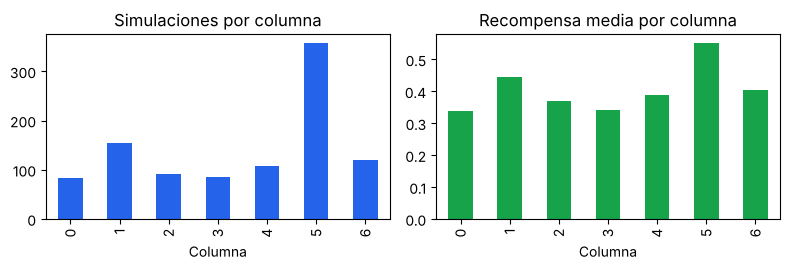

In [19]:
visitas = pd.Series(mcts.visitas_acciones).sort_index()
medias = pd.Series(mcts.metricas.valores_acciones).sort_index()
fig, ejes = plt.subplots(1, 2, figsize=(8, 2.8))
visitas.plot.bar(ax=ejes[0], color='#2563eb')
ejes[0].set_title('Simulaciones por columna')
medias.plot.bar(ax=ejes[1], color='#16a34a')
ejes[1].set_title('Recompensa media por columna')
for eje in ejes:
    eje.set_xlabel('Columna')
plt.tight_layout()
plt.show()

El agente elige la columna con más simulaciones. Con la misma semilla, las decisiones son reproducibles:

In [20]:
a = AgenteMCTS(juego, time_lim=300, semilla=42)
b = AgenteMCTS(juego, time_lim=300, semilla=42)
print('Jugadas elegidas:', a.decidir(medio_juego), 'y', b.decidir(medio_juego))
print('¿Mismas simulaciones por columna?:', a.visitas_acciones == b.visitas_acciones)

Jugadas elegidas: 0 y 0
¿Mismas simulaciones por columna?: True


---
## 6. Traza de la búsqueda <a class="anchor" id="traza"></a>

Además de las métricas, cada agente guarda una **traza** con lo que hizo en los primeros niveles del árbol. La interfaz gráfica la reproduce para animar la búsqueda paso a paso (y poder retroceder). Estos son los primeros eventos de un alfa-beta:

In [21]:
alfabeta = AgenteAlfaBeta(juego, max_lim=5, heuristica='h1')
alfabeta.decidir(medio_juego)
print('Eventos registrados:', len(alfabeta.traza))
for evento in alfabeta.traza.eventos[:8]:
    resumen = {k: v for k, v in evento.items() if k in
               ('tipo', 'camino', 'valor', 'alfa', 'beta', 'podadas')}
    print(resumen)

Eventos registrados: 146
{'tipo': 'entra', 'camino': (), 'alfa': -inf, 'beta': inf}
{'tipo': 'entra', 'camino': (3,), 'alfa': -inf, 'beta': inf}
{'tipo': 'entra', 'camino': (3, 2), 'alfa': -inf, 'beta': inf}
{'tipo': 'hoja', 'camino': (3, 2, 4), 'valor': 0.05314009661835749}
{'tipo': 'hoja', 'camino': (3, 2, 1), 'valor': 0.06763285024154589}
{'tipo': 'hoja', 'camino': (3, 2, 5), 'valor': 0.06280193236714976}
{'tipo': 'hoja', 'camino': (3, 2, 0), 'valor': 0.06038647342995169}
{'tipo': 'hoja', 'camino': (3, 2, 6), 'valor': 0.06038647342995169}


---
## 7. Comparación sobre la misma instancia <a class="anchor" id="comparacion"></a>

`comparar_jugada` ejecuta varias configuraciones sobre **el mismo tablero** y devuelve las métricas de cada una: tiempo, nodos generados, nodos expandidos y memoria. Es lo mismo que hace la pestaña *Comparar* de la interfaz.

In [22]:
configuraciones = [
    {'algoritmo': 'minimax', 'nivel': 'medio'},
    {'algoritmo': 'alfabeta', 'nivel': 'medio', 'heuristica': 'h1'},
    {'algoritmo': 'alfabeta', 'nivel': 'medio', 'heuristica': 'h2'},
    {'algoritmo': 'mcts', 'nivel': 'medio'},
]
filas = comparar_jugada(juego, medio_juego, configuraciones, semilla=0)
columnas = ['configuracion', 'accion', 'tiempo', 'nodos_generados',
            'nodos_expandidos', 'memoria_max', 'podas', 'optima']
pd.DataFrame(filas)[columnas]

,configuracion,accion,tiempo,nodos_generados,nodos_expandidos,memoria_max,podas,optima
0,Minimax d=4,6,0.014002,2284,360,5,0,None
1,Alfa-beta h1 d=5,3,0.041288,983,304,6,193,None
2,Alfa-beta h2 d=5,3,0.007440,728,234,6,139,None
3,MCTS N=1000,5,0.237945,12453,1000,1001,0,None


La columna `optima` vale `None` porque la instancia tiene demasiadas casillas vacías para resolverla de forma exacta (ver la sección 9).

**Comparación de tiempos.** Con la función `compara_funciones` del taller medimos el tiempo de CPU que toma decidir una jugada a medida que avanza una partida:

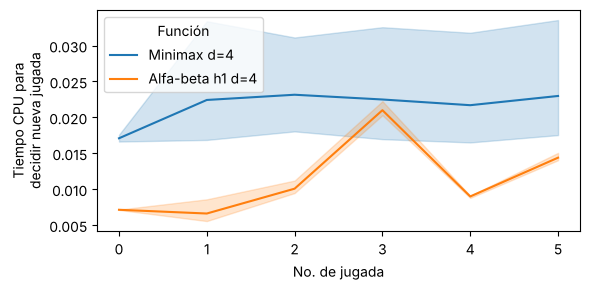

In [23]:
# Creamos la lista de funciones
agente_minimax = AgenteMinimax(juego, max_lim=4, semilla=0)
agente_alfabeta = AgenteAlfaBeta(juego, max_lim=4, heuristica='h1')
funs = [
    lambda s: agente_minimax.decidir(s),
    lambda s: agente_alfabeta.decidir(s),
]
# Creamos la lista de nombres de las funciones
nombres = ['Minimax d=4', 'Alfa-beta h1 d=4']
# Definimos una lista fija de jugadas para ambas funciones
jugadas = [3, 3, 2, 4, 3, 2]
s = juego.estado_inicial
lista_dfs = []
# Iteramos por jugadas
for i, a in enumerate(jugadas):
    data = compara_funciones(lista_funs=funs, lista_args=[[s], [s]],
                             lista_nombres=nombres, num_it=3)
    data['No. de jugada'] = i
    lista_dfs.append(data)
    s = juego.resultado(s, a)
data = pd.concat(lista_dfs, ignore_index=True)
# Graficando
fig, ax = plt.subplots(1, 1, figsize=(6, 3), tight_layout=True)
sns.lineplot(data=data, hue='Función', x='No. de jugada', y='tiempo_CPU', ax=ax)
ax.set_ylabel('Tiempo CPU para\ndecidir nueva jugada')
plt.show()

---
## 8. Partidas completas con las clases del curso <a class="anchor" id="partidas"></a>

Los agentes heredan de la clase `Agent` del curso, así que funcionan con `EnvfromGameAndPl2` (que une el juego con un segundo jugador automático) y con `Episode`. Aquí un alfa-beta (jugador 1) se enfrenta a un minimax (jugador 2):

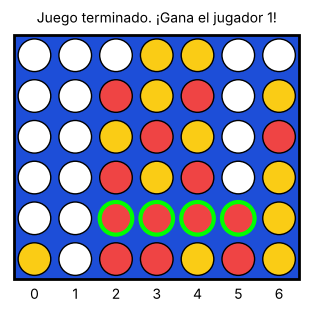

,episode,round,action,reward,done,model
10,0,10,6.0,0.0,False,Alfa-beta h1
11,0,11,5.0,0.0,False,Alfa-beta h1
12,0,12,5.0,0.0,False,Alfa-beta h1
13,0,13,NaN,18.0,True,Alfa-beta h1


In [24]:
# Inicialize game
juego = Conecta4()
# Create other player
other_player = AgenteMinimax(juego, max_lim=4, semilla=0)
# Create environment
env = EnvfromGameAndPl2(juego, other_player)
# Create player
player_alfa_beta = AgenteAlfaBeta(juego, max_lim=5, heuristica='h1')
# Create episode
episodio = Episode(environment=env,
                   agent=player_alfa_beta,
                   model_name='Alfa-beta h1',
                   num_rounds=21)
datos = episodio.run()
s = episodio.environment.state
juego.render(s, titulo=juego.give_result(s))
datos.tail(4)

La recompensa es 0 en los estados no terminales y la utilidad al terminar. También funcionan `Random` y `PlfromAlgo` del curso; por ejemplo, un alfa-beta contra un jugador aleatorio:

In [25]:
random.seed(0)
juego = Conecta4()
# Jugador creado a partir de un algoritmo (función estado -> acción)
agente_ab = AgenteAlfaBeta(juego, max_lim=4, heuristica='h1')
other_player = PlfromAlgo(lambda s: agente_ab.decidir(s))
env = EnvfromGameAndPl2(juego, other_player)
player_random = Random(choices=juego.acciones(juego.estado_inicial))
episodio = Episode(environment=env, agent=player_random,
                   model_name='Random', num_rounds=21)
episodio.run()
s = episodio.environment.state
print(juego.give_result(s), '(el jugador 2 es alfa-beta)')

Juego terminado. ¡Gana el jugador 2! (el jugador 2 es alfa-beta)


La función `jugar_partida` del proyecto hace lo mismo guardando además las métricas de cada jugada:

Secuencia de jugadas: [3, 2, 2, 3, 2, 3, 2, 2, 3, 5, 3, 0, 3, 5, 2, 0, 1, 5, 5, 5, 5, 1, 1, 6, 1, 6, 6, 6, 0, 0, 0, 0, 1, 1, 6, 6, 4, 4]
Ganador: 2 | fichas: 38


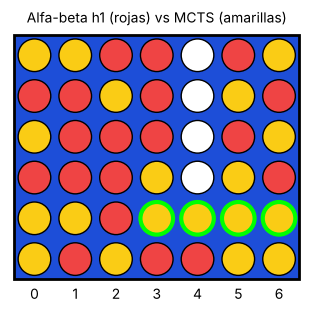

,tiempo,nodos_generados,nodos_expandidos,memoria_max
algoritmo,,,,
Alfa-beta h1 (d=5),0.015,573.684,184.105,5.842
MCTS (N=1000),0.172,7877.105,743.579,744.579


In [26]:
juego = Conecta4()
agente_1 = crear_agente(juego, 'alfabeta', 'medio', 'h1', semilla=1)
agente_2 = crear_agente(juego, 'mcts', 'medio', semilla=1)
partida = jugar_partida(juego, agente_1, agente_2)
print('Secuencia de jugadas:', partida['jugadas'])
print('Ganador:', partida['ganador'], '| fichas:', partida['num_fichas'])
registros = pd.DataFrame(partida['registros'])
juego.render(partida['estado_final'], titulo='Alfa-beta h1 (rojas) vs MCTS (amarillas)')
registros.groupby('algoritmo')[['tiempo', 'nodos_generados',
                                'nodos_expandidos', 'memoria_max']].mean().round(3)

---
## 9. Torneo y optimalidad <a class="anchor" id="torneo"></a>

**Torneo.** Todos contra todos en nivel fácil desde dos aperturas; cada pareja juega una partida con cada uno empezando.

In [27]:
configuraciones = [
    {'algoritmo': 'minimax', 'nivel': 'facil'},
    {'algoritmo': 'alfabeta', 'nivel': 'facil', 'heuristica': 'h1'},
    {'algoritmo': 'alfabeta', 'nivel': 'facil', 'heuristica': 'h2'},
    {'algoritmo': 'mcts', 'nivel': 'facil'},
    {'algoritmo': 'aleatorio'},
]
partidas = torneo(juego, configuraciones, aperturas=[[], [3, 3]], semilla=0)
columnas = ['configuracion', 'partidas', 'victorias', 'empates', 'derrotas',
            'puntos', 'tiempo_medio', 'generados_medio', 'memoria_max']
pd.DataFrame(tabla_posiciones(partidas))[columnas].round(4)

,configuracion,partidas,victorias,empates,derrotas,puntos,tiempo_medio,generados_medio,memoria_max
0,MCTS N=200,16,14,0,2,42,0.0481,2203.5617,201
1,Alfa-beta h1 d=2,16,12,0,4,36,0.0008,25.8371,3
2,Alfa-beta h2 d=2,16,8,1,7,25,0.0003,20.8120,3
3,Minimax d=2,16,4,1,11,13,0.0006,48.7628,3
4,Aleatorio,16,1,0,15,3,0.0000,0.0000,0


**Optimalidad.** En posiciones con pocas casillas vacías, `SolverExacto` calcula el valor minimax verdadero de cada jugada (explora hasta los estados terminales). Así se puede saber si la jugada de un agente es **óptima**. En la instancia "Final de partida" juega el jugador 2 y solo la columna 6 gana:

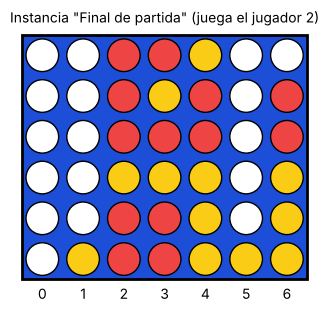

Valor exacto de cada columna: {0: 0, 1: 0, 5: 0, 6: 9}
Jugadas óptimas: [6]


In [28]:
final = juego.desde_jugadas([2, 4, 3, 1, 2, 4, 3, 4, 4, 3, 3, 2, 2, 3, 3, 5,
                             2, 6, 4, 6, 2, 6, 6, 4, 6])
juego.render(final, titulo='Instancia "Final de partida" (juega el jugador 2)')
solver = SolverExacto(juego)
print('Valor exacto de cada columna:', solver.valores_acciones(final))
print('Jugadas óptimas:', solver.jugadas_optimas(final))

In [29]:
filas = []
for nivel in ['facil', 'medio', 'dificil']:
    configuraciones = [
        {'algoritmo': 'minimax', 'nivel': nivel},
        {'algoritmo': 'alfabeta', 'nivel': nivel, 'heuristica': 'h1'},
        {'algoritmo': 'alfabeta', 'nivel': nivel, 'heuristica': 'h2'},
        {'algoritmo': 'mcts', 'nivel': nivel},
    ]
    filas += comparar_jugada(juego, final, configuraciones, semilla=0,
                             solver=solver)
pd.DataFrame(filas)[['configuracion', 'accion', 'optima', 'valor_exacto',
                     'tiempo', 'nodos_generados']].round(4)

,configuracion,accion,optima,valor_exacto,tiempo,nodos_generados
0,Minimax d=2,6,True,9,0.0001,19
1,Alfa-beta h1 d=2,0,False,0,0.0008,15
2,Alfa-beta h2 d=2,1,False,0,0.0001,12
3,MCTS N=200,6,True,9,0.0162,897
4,Minimax d=4,6,True,9,0.0015,218
5,Alfa-beta h1 d=5,5,False,0,0.0034,197
6,Alfa-beta h2 d=5,1,False,0,0.0017,170
7,MCTS N=1000,6,True,9,0.0621,2752
8,Minimax d=6,6,True,9,0.0137,1716
9,Alfa-beta h1 d=8,6,True,9,0.0203,900


La victoria necesita 9 jugadas más, por lo que ninguna búsqueda de profundidad 8 o menos puede "verla": depende de la heurística o de las simulaciones. Minimax no tiene heurística: elige al azar entre las jugadas que le parecen iguales (con esta semilla acertó).

---
## 10. Resultados de los experimentos del informe <a class="anchor" id="experimentos"></a>

El script `experimentos/ejecutar_experimentos.py` corre los experimentos completos (con semillas fijas) y guarda los datos en `experimentos/resultados/`. Aquí se leen las tablas resumen y las figuras.

In [30]:
carpeta = os.path.join('..', 'experimentos', 'resultados')
torneo_medio = pd.read_csv(os.path.join(carpeta, 'resumen_e2_torneo_medio.csv'))
columnas = ['configuracion', 'partidas', 'victorias', 'empates', 'derrotas',
            'pct_victorias', 'tiempo_medio', 'generados_medio', 'memoria_max']
print('Torneo en nivel medio')
torneo_medio[columnas].round(3)

Torneo en nivel medio


,configuracion,partidas,victorias,empates,derrotas,pct_victorias,tiempo_medio,generados_medio,memoria_max
0,Alfa-beta h1 d=5,64,56,3,5,87.500,0.034,1046.372,6
1,Alfa-beta h2 d=5,64,41,5,18,64.062,0.013,744.671,6
2,MCTS N=1000,64,39,3,22,60.938,0.211,9010.665,1001
3,Minimax d=4,64,18,1,45,28.125,0.026,2165.429,5
4,Aleatorio,64,0,0,64,0.000,0.000,0.000,0


In [31]:
torneo_dificil = pd.read_csv(os.path.join(carpeta, 'resumen_e2_torneo_dificil.csv'))
print('Torneo en nivel difícil')
torneo_dificil[columnas].round(3)

Torneo en nivel difícil


,configuracion,partidas,victorias,empates,derrotas,pct_victorias,tiempo_medio,generados_medio,memoria_max
0,MCTS N=5000,18,12,3,3,66.667,0.830,33230.149,5001
1,Alfa-beta h1 d=8,18,12,2,4,66.667,0.841,32248.831,9
2,Alfa-beta h2 d=8,18,7,2,9,38.889,0.266,21023.805,9
3,Minimax d=6,18,0,3,15,0.000,0.596,73512.285,7


In [32]:
print('Porcentaje de jugadas óptimas en 60 finales de partida')
optimalidad = pd.read_csv(os.path.join(carpeta, 'resumen_e4_optimalidad.csv'))
optimalidad.pivot(index='algoritmo', columns='nivel', values='optima')[
    ['facil', 'medio', 'dificil']].dropna()

Porcentaje de jugadas óptimas en 60 finales de partida


nivel,facil,medio,dificil
algoritmo,,,
Alfa-beta h1,61.7,93.3,96.7
Alfa-beta h2,63.3,91.7,96.7
MCTS,82.2,86.1,89.4
Minimax,65.6,86.1,90.6


In [33]:
print('h1 contra h2 a igual profundidad')
pd.read_csv(os.path.join(carpeta, 'resumen_e3_heuristicas.csv'))

h1 contra h2 a igual profundidad


,profundidad,partidas,gana_h1,empates,gana_h2
0,d=2,40,27,0,13
1,d=4,40,22,4,14
2,d=6,40,17,10,13


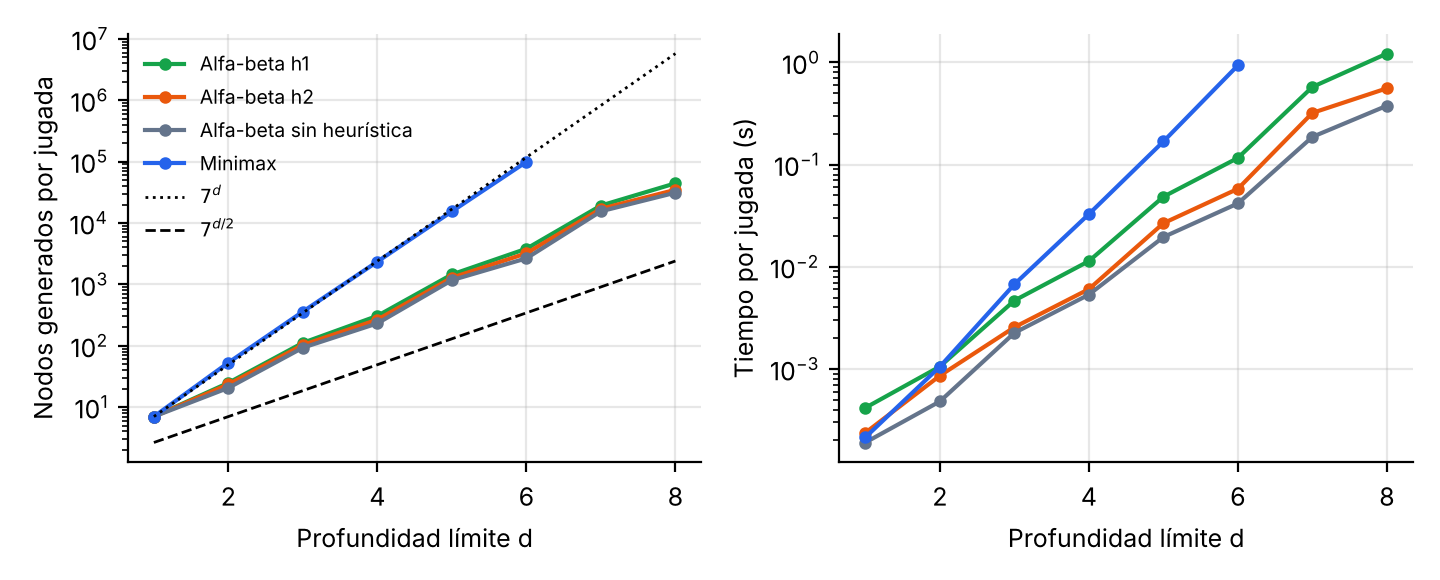

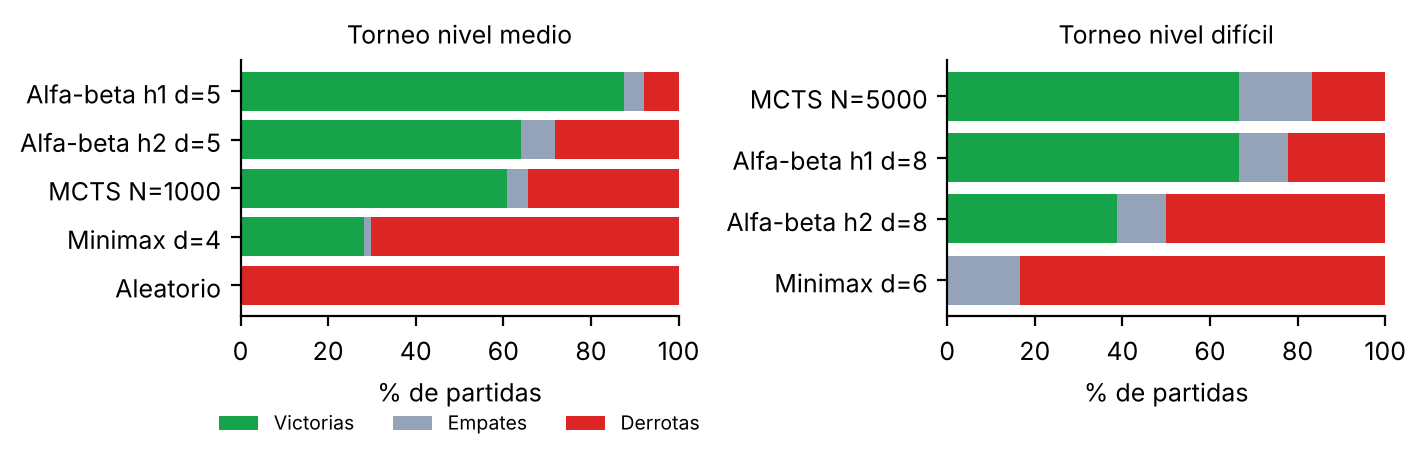

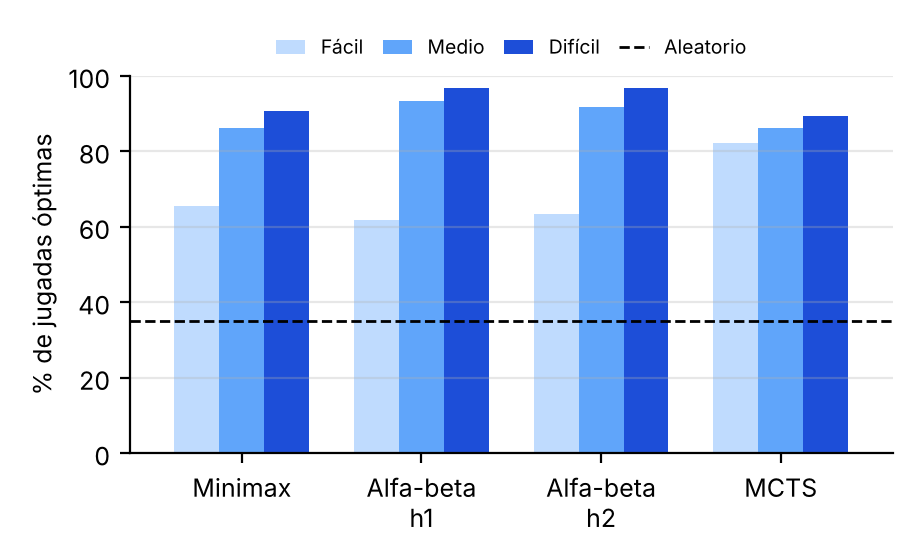

In [34]:
from IPython.display import Image, display
for figura in ['fig1_costo_profundidad.png', 'fig2_torneos.png',
               'fig3_optimalidad.png']:
    display(Image(os.path.join('..', 'experimentos', 'figuras', figura),
                  width=640))

---
## En este notebook se mostró

* La creación de una instancia del entorno `Conecta4`, sus atributos y sus métodos (`player`, `acciones`, `resultado`, `es_terminal`, `utilidad`), y cómo editar el estado inicial.
* Las dos funciones de evaluación, `h1` y `h2`.
* La aplicación de minimax con profundidad limitada, alfa-beta con cutoff y MCTS, con sus métricas y su traza.
* La comparación de los algoritmos sobre la misma instancia, en partidas completas y en torneos, y la verificación de optimalidad con el solucionador exacto.